# Decision Trees for binary classification

## Introduction
In this notebook I am using a decision tree as the model for predicting the mortality of patients following myocardial infarction. The benefit of using a decision tree model is that their flowchart-like structure makes them easy to visualise. This is particularly useful when applied to healthcare data as clinicians can easily see which features are the most important in the classification and decisions can be traced back. The downside of using a decision tree is that it is prone to overfitting; therefore, the choice of hyperparameters are important. 

## Exploratory Data Analysis (EDA) and Imputation

This dataset included missingness and class imbalance which are addressed throughout the notebook. The data is split into training, validation and test data. In this project, instead of using cross-validation, I have used holdout validation because cross-validation would require performing imputation separately within each training fold. Holdout validation simplifies pre-processing by only needing to fit the imputation method once on the training data, making it computationally simpler. A limitation of this approach is that the estimated model performance depends on the particular split of the data, potentially making the results less robust than if obtained through cross-validation.


In [2]:
#Importing the relevant libraries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#Importing the cross validation data split 
df_train = pd.read_csv("training_data.csv")
df_validate = pd.read_csv("validation_data.csv")
df_test = pd.read_csv("test_data.csv")

### Exploring missingness

The missing values in each feature are explored to determine how best to address missingness. Removing every observation containing missing values could substantially reduce the size of the training data. Instead, a combination of feature removal and statistical imputation is used.

In [3]:
#Assessing if there are any null values 
missing_values = df_train.isnull().sum()

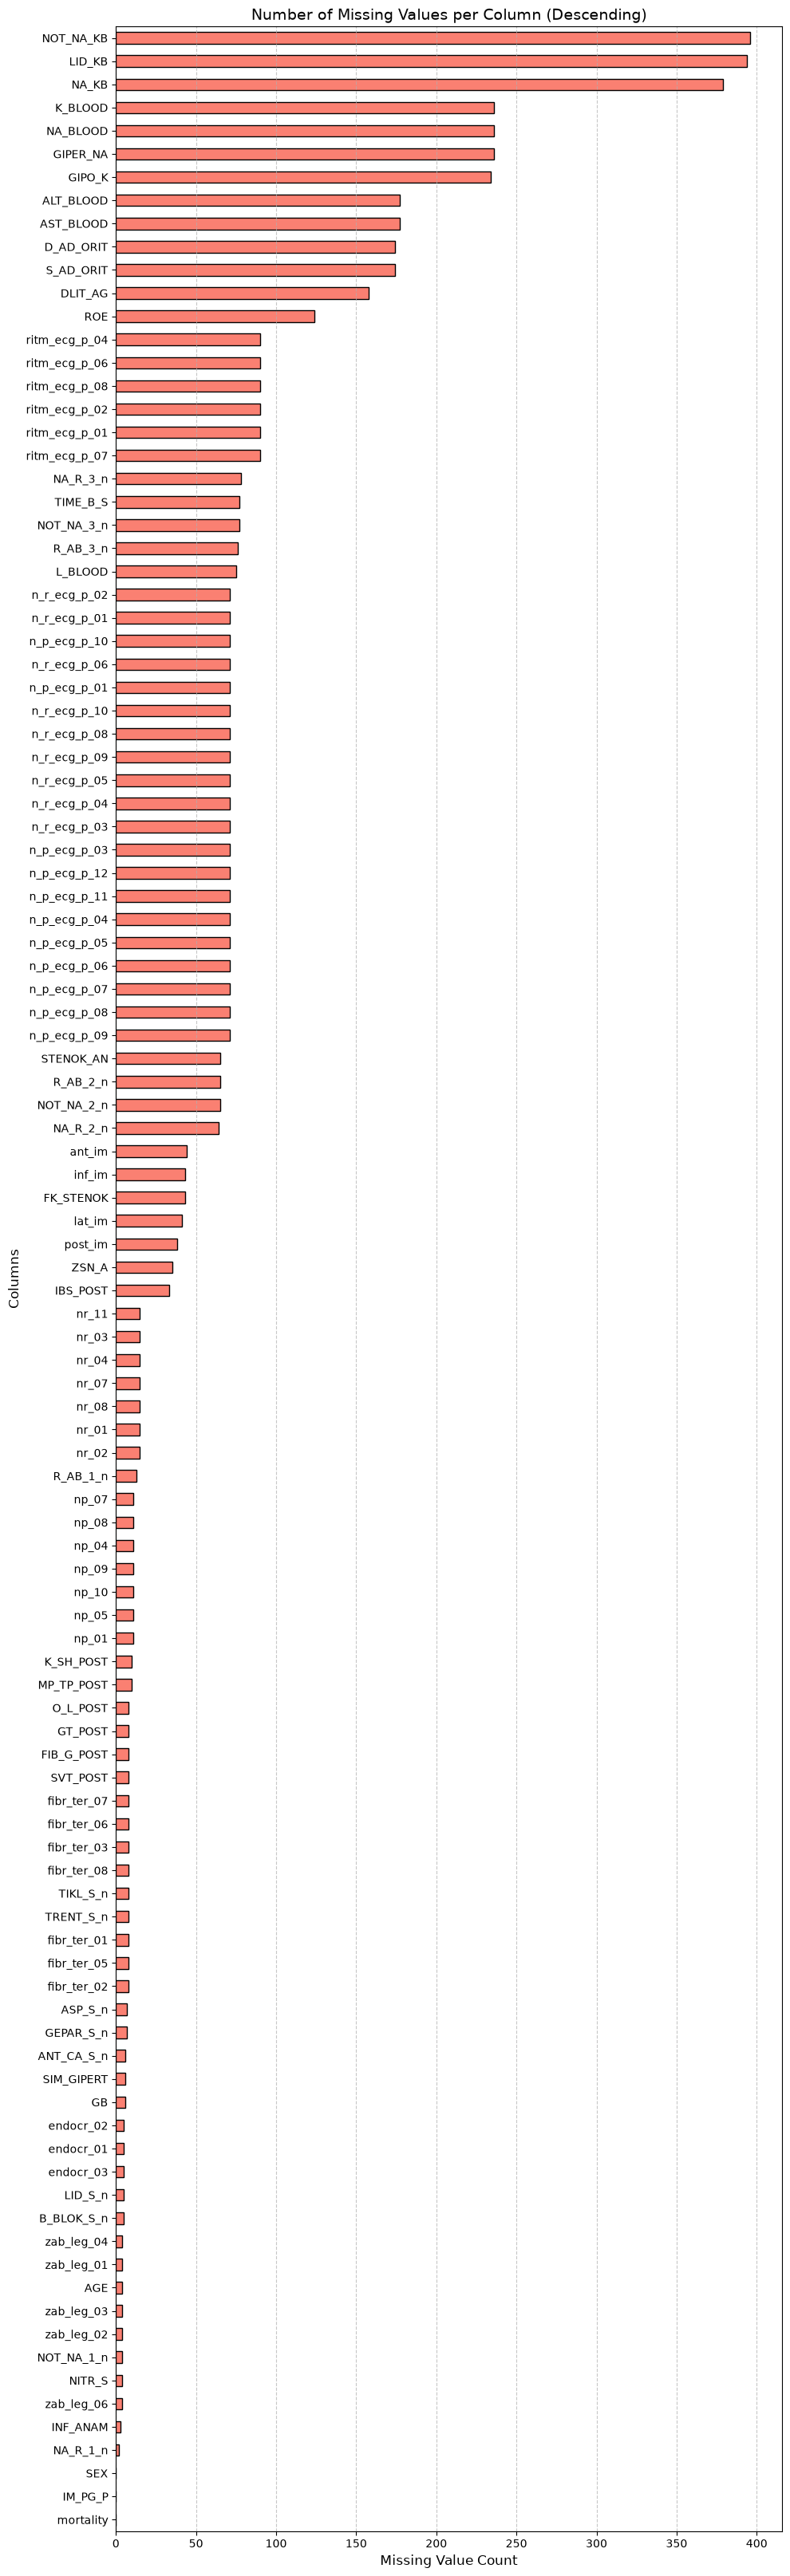

In [4]:
#PLOT OF MISSING VALUES

#Sort missing values in descending order
missing_values = missing_values.sort_values(ascending=False)

#Create a horizontal bar plot and adjust figure height for readability
plt.figure(figsize=(10, max(6, len(missing_values) * 0.3))) # Dynamically scales height based on column count
missing_values.plot(kind='barh', color='salmon', edgecolor='black')

#Customize the graph labels and layout
plt.title('Number of Missing Values per Column (Descending)', fontsize=14)
plt.xlabel('Missing Value Count', fontsize=12)
plt.ylabel('Columns', fontsize=12)
plt.gca().invert_yaxis()  # Puts the column with the highest missing values at the very top
plt.grid(axis='x', linestyle='--', alpha=0.7)

#Display the plot
plt.tight_layout()
plt.show()

The bar graph above shows the number of missing values present in each column. It shows that missing values are not distributed equally across the dataset, with certain features containing considerably more missing values than others.

### Imputation

The three variables containing the highest numbers of missing observations were removed from the training and validation datasets. This is because they had a substantial number of null values, with substantially more than the other features, so imputing the median or mode into the features would not be very informative. For numerical variables, median imputation was chosen as it is less sensitive to outliers than the mean. For categorical variables, mode imputation was used. 

The training dataset was used to calculate the imputation values and these were then applied to the validation data to prevent the validation dataset informing imputed values (data leakage).


In [5]:
# Identify the top 3 columns with the most missing values
top_3_missing = df_train.isnull().sum().nlargest(3).index

print("Columns being dropped:")
print(top_3_missing)

# Drop these columns from both datasets
df_train = df_train.drop(columns=top_3_missing)
df_validate = df_validate.drop(columns=top_3_missing)

# Check dimensions
print("Training:", df_train.shape)
print("Validation:", df_validate.shape)

Columns being dropped:
Index(['NOT_NA_KB', 'LID_KB', 'NA_KB'], dtype='str')
Training: (1020, 105)
Validation: (340, 105)


In [6]:
from sklearn.impute import SimpleImputer

# Continuous numerical variables (including AGE)
numerical_cols = [
    'AGE',
    'S_AD_ORIT',
    'D_AD_ORIT',
    'K_BLOOD',
    'NA_BLOOD',
    'ALT_BLOOD',
    'AST_BLOOD',
    'L_BLOOD',
    'ROE'
]

# Categorical variables
categorical_cols = [
    col for col in df_train.columns
    if col not in numerical_cols + ['mortality']
]

# Initialise imputers
median_imputer = SimpleImputer(strategy='median')
mode_imputer = SimpleImputer(strategy='most_frequent')

# Median imputation for numerical variables (including AGE)
df_train[numerical_cols] = median_imputer.fit_transform(
    df_train[numerical_cols]
)

# Mode imputation for categorical variables
df_train[categorical_cols] = mode_imputer.fit_transform(
    df_train[categorical_cols]
)

Values were imputed into the training dataset using fit_transform() and then this was applied to the validation data using the transform() method to ensure the same median and mode values from the training data were applied to the validation data.

In [7]:
# Median imputation for validation data
df_validate[numerical_cols] = median_imputer.transform(
    df_validate[numerical_cols]
)

# Mode imputation for validation data
df_validate[categorical_cols] = mode_imputer.transform(
    df_validate[categorical_cols]
)

In [8]:
# Check remaining missing values
print("Training missing values:")
print(df_train.isnull().sum().sum())

print("Validation missing values:")
print(df_validate.isnull().sum().sum())

# Check dataset dimensions
print("Training shape:", df_train.shape)
print("Validation shape:", df_validate.shape)

Training missing values:
0
Validation missing values:
0
Training shape: (1020, 105)
Validation shape: (340, 105)


In [9]:
print(df_train['mortality'].isnull().sum())
print(df_validate['mortality'].isnull().sum())

0
0


Using the checks above there are no missing values remaining in the training or validation datasets. There is also no missingness present in the mortality column which is important for training the model later.


### Class imbalance

In this dataset there is a class imbalance with a lot more patients surviving than dying. Approximately 84% of patients survived while 16% of patients died. Therefore, when using accuracy as a performance metric, the model would achieve 84% accuracy if it simply predicted that every patient survived. This is unhelpful as it is important to predict whether a patient needs medical intervention. Therefore, predicting if a patient is going to die is important for this model and using accuracy alone is not a suitable performance metric.

Due to the class imbalance the decision tree might favour the majority class (a patient surviving). Therefore, to investigate the impact of the class imbalance, the decision trees are trained with and without class weighting in the next section to ultimately choose the most appropriate model.

In [10]:
#This is an unbalanced data set
print(df_train['mortality'].value_counts())

#Percentage of 0s and 1s
print(df_train["mortality"].value_counts(normalize=True) * 100)

mortality
0    857
1    163
Name: count, dtype: int64
mortality
0    84.019608
1    15.980392
Name: proportion, dtype: float64


## Decision tree classification and using validation data set

As decision trees can be prone to overfitting, in this section different selections of the `max_depth` parameter are investigated. Increasing `max_depth` allows the tree to capture more complex relationships, but also increases the risk of overfitting. On the other hand, a smaller `max_depth` can result in underfitting, as the model cannot capture sufficient detail. Therefore, performance on the training and validation datasets is compared across different `max_depth` values to strike a balance between generalisation and model complexity.

The criterion chosen in the decision tree classifier is Gini impurity which is defined as 
$$
G = 1 - p_0^2 - p_1^2
$$
where $p_0$ and $p_1$ represent the proportions of observations belonging to classes 0 and 1, respectively. This criterion was chosen due to its efficiency in creating splits that maximise class separation.

To address the class imbalance the built-in `class_weight` parameter in the DecisionTreeClassifier is set to `None` (the default) or `'balanced'`. The performance is then compared to see if assigning greater weight to misclassifying patients in the minority class makes a meaningful difference to the model.


### Performance metrics used in this section:
Performance metrics have been discussed in other parts of this project, but they are summarised below for convenience.

- Accuracy score: Measures the proportion of predictions that the model classifies correctly.
- Precision score: Measures the proportion of positive predictions that are actually positive.
- Recall score: Measures the proportion of actual positive observations that the model correctly identifies. High recall indicates that the model produces relatively few false negatives.
- F1 score: F1 score balances precision and recall, penalising models that perform poorly on either metric.
- Balanced accuracy score: Measures the average recall across the positive and negative classes.
- Matthews correlation coefficient: Measures the correlation between predicted and actual classifications, taking into account all four outcomes of the confusion matrix.
- ROC-AUC: Measures the trade-off between correctly identifying positive observations and incorrectly classifying negative observations as positive.
- Confusion matrix: Summarises the number of correct and incorrect predictions made by a classification model.

In [11]:
# Load libraries
from sklearn.tree import DecisionTreeClassifier 
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

In [12]:
# Training data
X_train = df_train.drop(columns=['mortality'])
y_train = df_train['mortality']

# Validation dat
X_validate = df_validate.drop(columns=['mortality'])
y_validate = df_validate['mortality']

# Define maximum depths to investigate
depths = range(1, 16)

# List to store results
results = []

# Loop through different maximum depths
for depth in depths:

    # Loop through balanced and unbalanced models
    for weight in [None, 'balanced']:

        # Initialise decision tree
        dt = DecisionTreeClassifier(
            criterion='gini',
            max_depth=depth,
            class_weight=weight,
            random_state=42
        )

        # Train the decision tree
        dt.fit(X_train, y_train)

        # Make predictions
        y_train_pred = dt.predict(X_train)
        y_validate_pred = dt.predict(X_validate)

        # Calculate F1 scores
        train_f1 = f1_score(y_train, y_train_pred)
        validate_f1 = f1_score(y_validate, y_validate_pred)

        # Store results
        results.append({
            'Max Depth': depth,
            'Class Weight': weight if weight else 'None',
            'Training F1': train_f1,
            'Validation F1': validate_f1
        })

# Create results DataFrame
depth_results = pd.DataFrame(results)

depth_results = depth_results.pivot(
    index='Max Depth',
    columns='Class Weight',
    values=['Training F1', 'Validation F1']
)

# Rename columns
depth_results.columns = [
    'Training (Balanced)',
    'Training (Unbalanced)',
    'Validation (Balanced)',
    'Validation (Unbalanced)'
]

# Round F1 scores 
depth_results = depth_results.round(4)

depth_results

,Training (Balanced),Training (Unbalanced),Validation (Balanced),Validation (Unbalanced)
Max Depth,,,,
1,0.2827,0.3628,0.1967,0.2609
2,0.4196,0.4092,0.4304,0.3349
3,0.4019,0.5584,0.3662,0.3303
4,0.4155,0.5160,0.3714,0.3827
5,0.5172,0.5808,0.3333,0.3544
6,0.6185,0.6369,0.3896,0.3893
7,0.7063,0.7031,0.4048,0.3910
8,0.7704,0.7386,0.4045,0.3333
9,0.8378,0.7931,0.4211,0.3871


This shows how the F1 score changes depending on the `max_depth` parameter in the decision tree classifier. The F1 score for the training data and validation data, for balanced and unbalanced decision trees, are also compared side by side for reference.

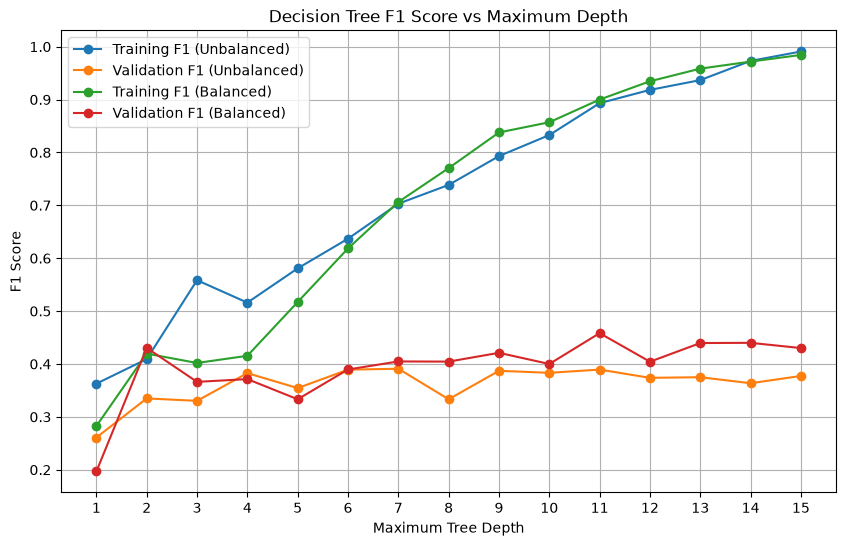

In [13]:
plt.figure(figsize=(10, 6))

#Training F1 - unbalanced
plt.plot(
    depths,
    depth_results['Training (Unbalanced)'],
    marker='o',
    label='Training F1 (Unbalanced)'
)

#Validation F1 - unbalanced
plt.plot(
    depths,
    depth_results['Validation (Unbalanced)'],
    marker='o',
    label='Validation F1 (Unbalanced)'
)

#Training F1 - balanced
plt.plot(
    depths,
    depth_results['Training (Balanced)'],
    marker='o',
    label='Training F1 (Balanced)'
)

#Validation F1 - balanced
plt.plot(
    depths,
    depth_results['Validation (Balanced)'],
    marker='o',
    label='Validation F1 (Balanced)'
)

plt.xlabel('Maximum Tree Depth')
plt.ylabel('F1 Score')
plt.title('Decision Tree F1 Score vs Maximum Depth')

plt.xticks(depths)
plt.legend()
plt.grid(True)

plt.show()

This graph illustrates how increasing the `max_depth` parameter does not necessarily increase the performance when the model is applied to unseen data. It shows overfitting: when the depth of the decision tree is 15, the training F1 score is almost perfect, whereas the validation F1 score decreases.

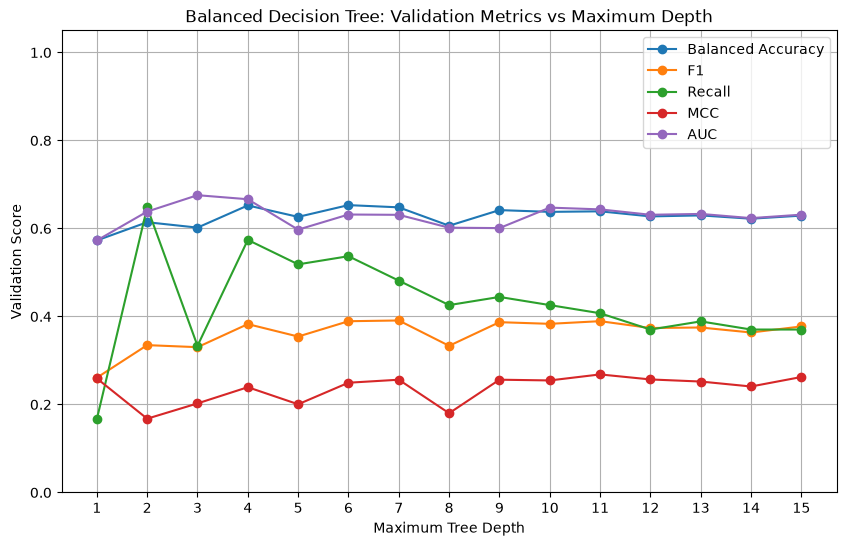

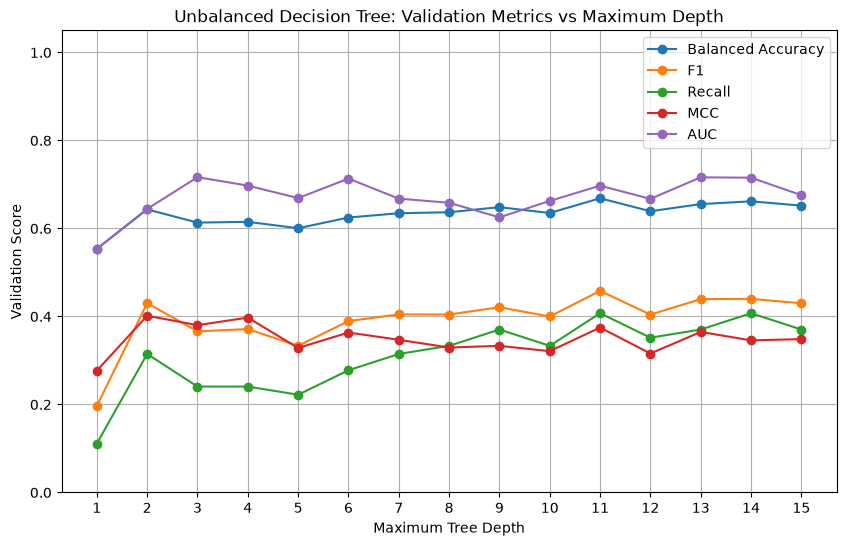

In [14]:
depths = range(1, 16)

# Define evaluation metrics
metrics = {
    'Balanced Accuracy': balanced_accuracy_score,
    'F1': f1_score,
    'Recall': recall_score,
    'MCC': matthews_corrcoef
}

# Store validation metrics
results = {
    'Balanced': {metric: [] for metric in [*metrics, 'AUC']},
    'Unbalanced': {metric: [] for metric in [*metrics, 'AUC']}
}

# Train and evaluate decision trees
for depth in depths:
    for model_type, weight in [('Balanced', 'balanced'),
                               ('Unbalanced', None)]:

        tree = DecisionTreeClassifier(
            max_depth=depth,
            class_weight=weight,
            random_state=42
        )

        tree.fit(X_train, y_train)

        # Predictions
        y_pred = tree.predict(X_validate)
        y_prob = tree.predict_proba(X_validate)[:, 1]

        # Calculate evaluation metrics
        for metric, function in metrics.items():
            results[model_type][metric].append(
                function(y_validate, y_pred)
            )

        # Calculate AUC separately
        results[model_type]['AUC'].append(
            roc_auc_score(y_validate, y_prob)
        )


# Plot validation metrics
for model_type in results:

    plt.figure(figsize=(10, 6))

    for metric, scores in results[model_type].items():
        plt.plot(
            depths,
            scores,
            marker='o',
            label=metric
        )

    plt.xlabel('Maximum Tree Depth')
    plt.ylabel('Validation Score')
    plt.title(f'{model_type} Decision Tree: Validation Metrics vs Maximum Depth')

    plt.xticks(depths)
    plt.ylim(0, 1.05)
    plt.legend()
    plt.grid(True)

    plt.show()

The graphs above investigate the effect of the maximum depth on the performance of the decision tree, models were trained with maximum depths ranging from 1 to 15. For each depth, two models were trained, one using balanced class weights and one without class weighting. To compare the models, I have chosen to prioritise recall over the F1 score as in a clinical setting false negatives are generally more harmful than false positives. For the balanced decision tree, a depth of 4 has the best recall performance whereas for the unbalanced decision tree, a depth of 11 has the best recall performance. 

### Addressing the class imbalance


The class imbalance in the dataset is particularly important when predicting mortality as the model may favour predicting that a patient survives. In a healthcare setting, incorrectly predicting that a patient will survive when they are at risk of dying could have serious consequences. Therefore, it is important to consider performance metrics other than accuracy.

To investigate the effect of class imbalance, two decision trees were trained. The first used `class_weight='balanced'`, which increases the weight assigned to observations belonging to the minority class when calculating the tree's splitting criterion, while the second used no class weighting. Based on the performance metrics in the previous graph, the balanced decision tree was assigned a maximum depth of 4 and the unbalanced tree a maximum depth of 11.

The confusion matrices were also plotted to compare the number of correct and incorrect predictions made by each model. In particular, the number of false negatives is important as these represent patients who died but were incorrectly predicted to survive.

In [15]:
# Initialise final decision trees
dt_final_balanced = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    class_weight='balanced',
    random_state=42
)


dt_final_unbalanced = DecisionTreeClassifier(
    criterion='gini',
    max_depth=11,
    random_state=42
)

# Train final decision tree

dt_final_balanced.fit(X_train, y_train)
dt_final_unbalanced.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",11
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at

,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Validation MCC,Validation Balanced Accuracy,Validation AUC
Model,,,,,,,
Balanced,0.706,0.287,0.574,0.383,0.239,0.652,0.667
Unbalanced,0.847,0.524,0.407,0.458,0.375,0.669,0.697


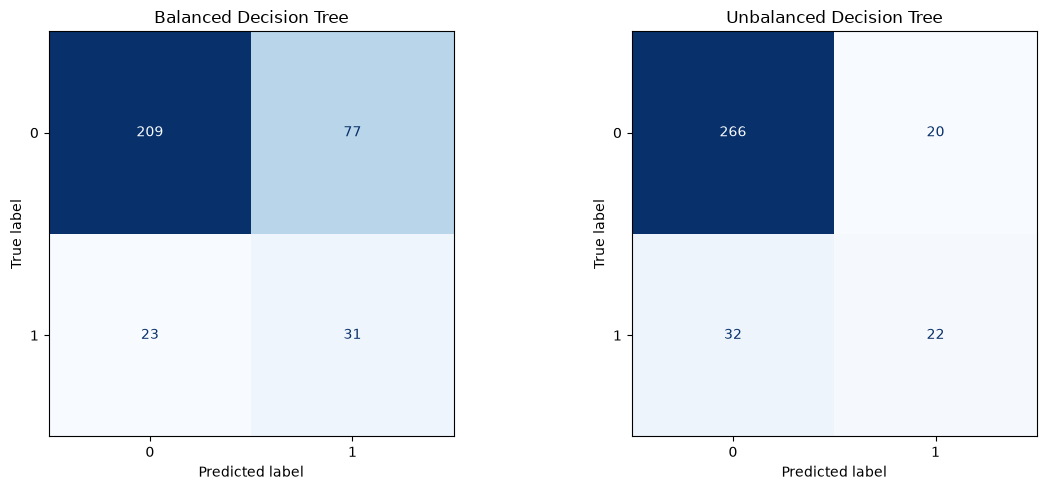

In [16]:
# Create comparison DataFrame
comparison_results = []

for name, model in [
    ('Balanced', dt_final_balanced),
    ('Unbalanced', dt_final_unbalanced)
]:
    y_pred = model.predict(X_validate)
    y_prob = model.predict_proba(X_validate)[:, 1]

    comparison_results.append({
        'Model': name,
        'Validation Accuracy': accuracy_score(y_validate, y_pred),
        'Validation Precision': precision_score(
            y_validate, y_pred, zero_division=0
        ),
        'Validation Recall': recall_score(y_validate, y_pred),
        'Validation F1': f1_score(y_validate, y_pred),
        'Validation MCC': matthews_corrcoef(y_validate, y_pred),
        'Validation Balanced Accuracy': balanced_accuracy_score(
            y_validate, y_pred
        ),
        'Validation AUC': roc_auc_score(y_validate, y_prob)
    })

comparison = pd.DataFrame(comparison_results).set_index('Model')
display(comparison.round(3))

# Predictions using validation data
y_pred_balanced = dt_final_balanced.predict(X_validate)
y_pred_unbalanced = dt_final_unbalanced.predict(X_validate)

# Calculate confusion matrices
cm_balanced = confusion_matrix(y_validate, y_pred_balanced)
cm_unbalanced = confusion_matrix(y_validate, y_pred_unbalanced)

# Plot confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Balanced decision tree
ConfusionMatrixDisplay(
    confusion_matrix=cm_balanced
).plot(ax=axes[0], cmap='Blues', colorbar=False)

axes[0].set_title('Balanced Decision Tree')

# Unbalanced decision tree
ConfusionMatrixDisplay(
    confusion_matrix=cm_unbalanced
).plot(ax=axes[1], cmap='Blues', colorbar=False)

axes[1].set_title('Unbalanced Decision Tree')

plt.tight_layout()
plt.show()

### Selecting the final model

The balanced and unbalanced decision trees were compared using their performance on the validation dataset. The unbalanced model outperformed the balanced model across most performance metrics. However, the balanced model achieved higher recall, indicating that it correctly identified a greater proportion of patients who later died. In a clinical setting, false negatives are particularly concerning because they represent patients at risk of death who are incorrectly classified as survivors. 

The balanced decision tree with a maximum depth of 4 was selected as the final model. This decision reflects a preference for reducing false negatives in a healthcare domain, although the greater number of false positives could lead to unnecessary clinical interventions. 

A limitation of this selection process is its reliance on a single validation split. Using k-fold cross-validation, instead of holdout validation, could provide a more robust assessment of model performance and help determine whether the observed differences between models are consistent across different subsets of the data.


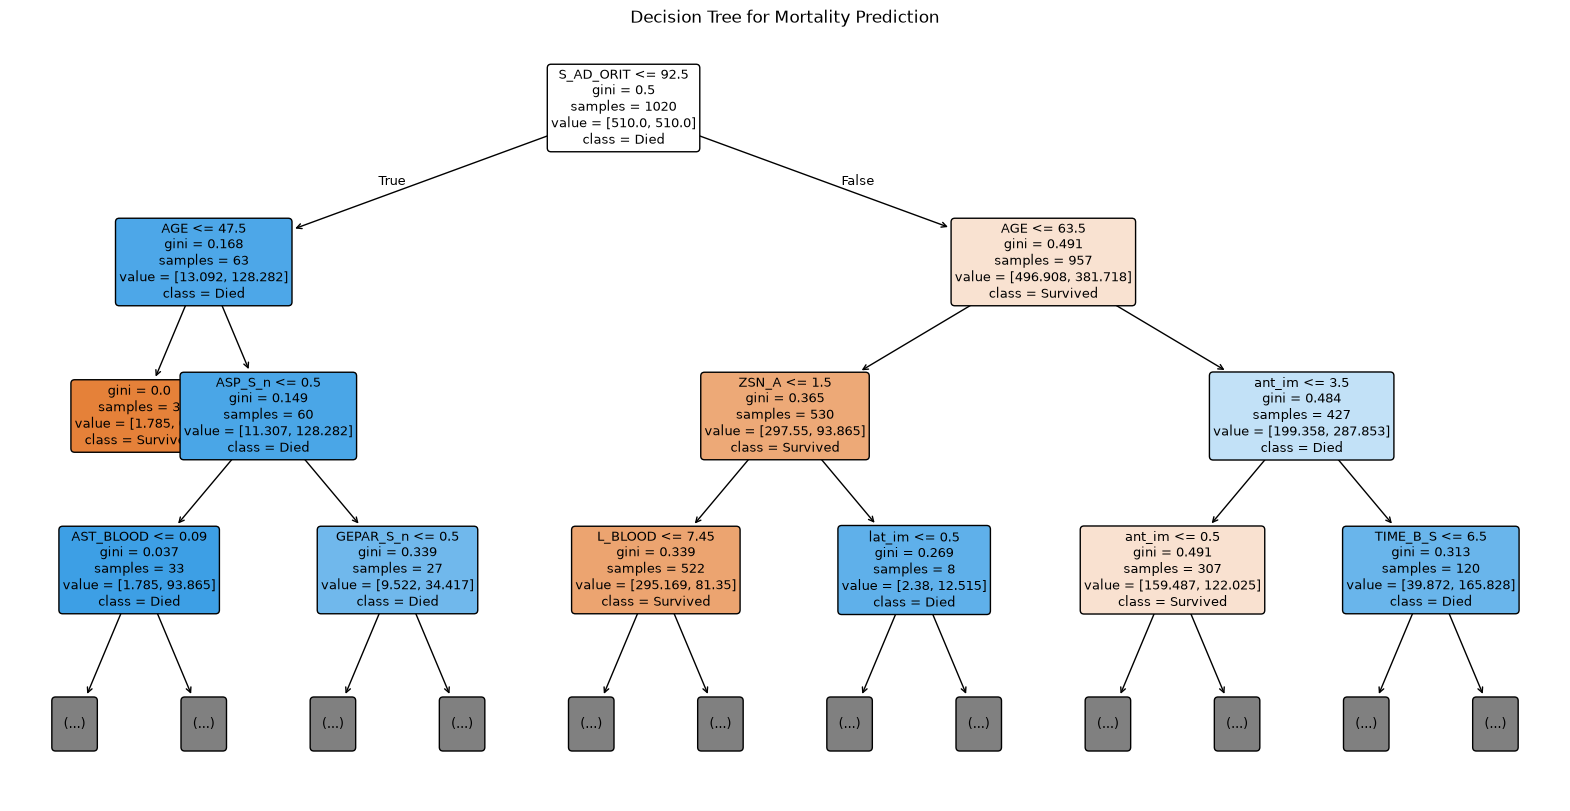

In [17]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    dt_final_balanced,
    feature_names=X_train.columns,
    class_names=['Survived', 'Died'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title('Decision Tree for Mortality Prediction')
plt.show()

The final decision tree was visualised using the `plot_tree()` function. The plot displays the first three levels of the tree to make the structure easier to interpret. Each node represents a decision based on a particular feature and threshold, with observations being split into different groups depending on whether they satisfy the condition. The visualisation allows us to examine which features are used in the initial splits and how the decision tree classifies patients. 

## Test data
Before evaluating the final model, the test dataset was pre-processed using the same methods applied to the training and validation datasets. The three features containing the most missing values in the training data were removed and the remaining missing values were imputed using the median and mode values calculated from the training data. The dataset was then checked for any remaining missing values before being used to evaluate the final model.

In [18]:
# Drop the same 3 columns removed from the training dataset
df_test = df_test.drop(columns=top_3_missing)

# Apply median imputation using training medians
df_test[numerical_cols] = median_imputer.transform(
    df_test[numerical_cols]
)

# Apply mode imputation using training modes
df_test[categorical_cols] = mode_imputer.transform(
    df_test[categorical_cols]
)

# Check remaining missing values
print("Missing values:", df_test.isnull().sum().sum())

Missing values: 0


In [19]:
# Test predictors and target
X_test = df_test.drop(columns=['mortality'])
y_test = df_test['mortality']

# Ensure predictors have the same order as training
X_test = X_test[X_train.columns]

# Predict mortality on unseen test data
y_test_pred  = dt_final_balanced.predict(X_test)

In [24]:
### Performance metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred, zero_division=0)
test_recall = recall_score(y_test, y_test_pred, zero_division=0)
test_f1 = f1_score(y_test, y_test_pred, zero_division=0)
mcc = matthews_corrcoef(y_test, y_test_pred)
ba_test = balanced_accuracy_score(y_test, y_test_pred)


#Results
print("Final Decision Tree Performance")
print("-------------------------------")
print("Test Accuracy:", test_accuracy)
print("Test Precision:", test_precision)
print("Test Recall:", test_recall)
print("Test F1-score:", test_f1)
print("Matthews Correlation Coefficient:", mcc)
print("Balanced accuracy score:", ba_test)

Final Decision Tree Performance
-------------------------------
Test Accuracy: 0.7323529411764705
Test Precision: 0.336283185840708
Test Recall: 0.7037037037037037
Test F1-score: 0.4550898203592814
Matthews Correlation Coefficient: 0.3425507715749248
Balanced accuracy score: 0.7207329707329708


To evaluate the performance of the final decision tree, several performance metrics were calculated using the test dataset. As the dataset contains a class imbalance, accuracy alone can give a misleading indication of the model's performance. Therefore, the F1-score and recall were used as the main performance metrics with recall being particularly important in this application.

The balanced accuracy and Matthews correlation coefficient were also calculated to provide additional measures of performance that are more informative when working with imbalanced datasets. Sources that describe both metrics are included in the references section. As Matthews correlation coefficient takes into account true and false positives and negatives and can be calculated directly from the confusion matrix, this performance metric would be more informative than using accuracy. However, when selecting the balanced model, the recall score was prioritised over precision which would in turn affect the Matthews correlation coefficient.

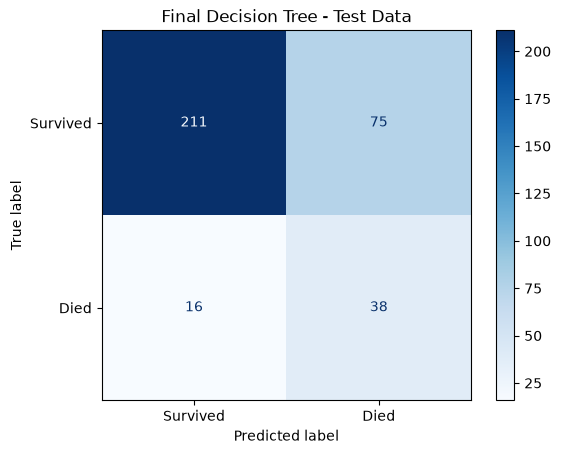

In [21]:
#Confusion matrix
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

#Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Survived', 'Died']
)

disp.plot(cmap='Blues')

plt.title('Final Decision Tree - Test Data')
plt.show()

The confusion matrix was plotted to further investigate the performance of the final decision tree. As when evaluating the balanced model on the validation data, the test data show that there are more true positives than false negatives (i.e. recall is relatively high) ; however, there are still a lot of false positives. This suggests that for this model to be useful in a real-world setting the decision tree's precision would need to be improved.

Decision Tree AUC Score: 0.7926


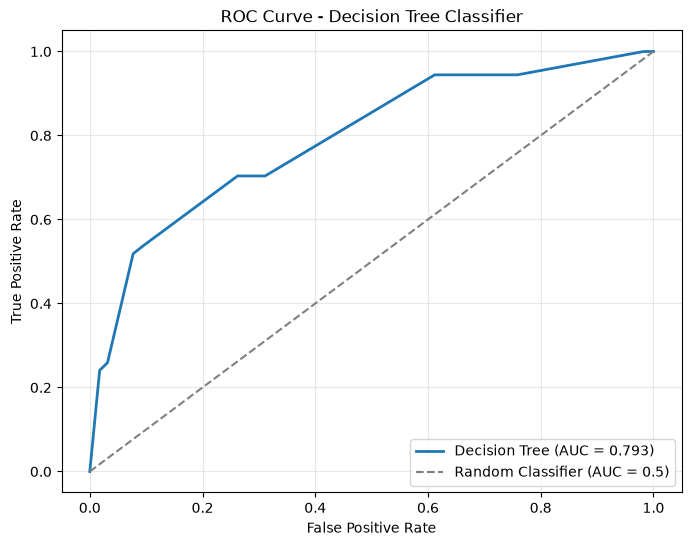

In [22]:
y_prob = dt_final_balanced.predict_proba(X_test)[:, 1]

#Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

#Calculate AUC score
auc_score = roc_auc_score(y_test, y_prob)

print(f"Decision Tree AUC Score: {auc_score:.4f}")

plt.figure(figsize=(8, 6))

#Plot ROC curve
plt.plot(
    fpr,
    tpr,
    label=f"Decision Tree (AUC = {auc_score:.3f})",
    linewidth=2
)

#Random classifier line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="grey",
    label="Random Classifier (AUC = 0.5)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Decision Tree Classifier")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.show()

The receiver operating characteristic (ROC) curve was plotted to further evaluate the classification performance of the decision tree. The ROC curve shows the relationship between recall and the false positive rate at different classification thresholds. The area under the curve (AUC) was calculated to provide a single measure of how well the model distinguishes between patients who survive and patients who die. An AUC of 0.5 would indicate that the model performs no better than random classification. Therefore, the AUC of 0.793 achieved for this model suggests that the trade-off between correctly identifying positive observations and incorrectly classifying negative observations as positive is reasonable. However, as the dataset is imbalanced, the ROC-AUC score should be considered alongside precision, recall and F1-score.


## Conclusion 
In this notebook, a decision tree classifier was used to predict patient mortality following myocardial infarction. The dataset contained missing values and class imbalance, which were addressed through feature removal, statistical imputation and the investigation of class weighting.

Different maximum depths were investigated to examine the effect of model complexity on performance and to reduce the risk of overfitting. Balanced and unbalanced decision trees were also compared to investigate whether class weighting improved the classification of patients in the minority class. 

Balanced and unbalanced decision trees were compared using several performance metrics. Although the unbalanced model achieved higher scores across most metrics, the balanced model had a higher recall score. As false negatives are particularly concerning when predicting mortality, a balanced decision tree with a maximum depth of 4 was selected as the final model.

The choice prioritises recall over precision because failing to identify patients at risk of death may have more serious consequences than a false alarm. However, the associated false positives remain a limitation for potential real-world clinical use.

An extension of this analysis would involve using k-fold cross-validation to obtain a more robust estimate of model performance. The model could also be improved by investigating other hyperparameters rather than just tackling `max_depth`, for example by conducting a more rigorous hyperparameter tuning method (e.g. using grid search).



## References

https://archive.ics.uci.edu/dataset/579/myocardial+infarction+complications

 https://developers.google.com/machine-learning/crash-course/overfitting/imbalanced-datasets

 https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
 
 https://www.datacamp.com/tutorial/decision-tree-classification-python

https://towardsdatascience.com/the-explanation-you-need-on-binary-classification-metrics-321d280b590f/

https://arxiv.org/html/1410.5330v1

https://scikit-learn.org/stable/modules/generated/sklearn.metrics.matthews_corrcoef.html

https://pmc.ncbi.nlm.nih.gov/articles/PMC9938573/

https://medium.com/@ayeshagunarathne/balanced-accuracy-for-imbalanced-binary-multi-class-medical-image-classification-80d490161d5c

https://medium.com/@jangdaehan1/understanding-gini-impurity-in-decision-trees-a-deep-dive-into-supervised-learning-5a05d5616a00

https://www.analyticsvidhya.com/blog/2024/06/data-science-in-medicine/
